# 07_eval / cross_dataset_eval.ipynb

**Purpose:** Formal **out-of-distribution** evaluation of the GSAF fusion model on:

1. **MMFakeBench test** (held-out — neither train nor val_tune)
2. **VERITE test** (real-world OOC pairs, never seen during training)

This is the most important table for the paper because it shows the model generalizes beyond the training distribution.

**Inputs:**
- `cache/fusion/fusion_predictions.csv`
- `cache/fusion/fusion_thresholds.json`
- Per-stream prediction CSVs in `cache/stream_*/`
- `data/processed/ooc_pairs/manifests/all.csv` (fallback for dataset/split)

**Outputs:**
- `paper/tables/cross_dataset_eval_mmfakebench.csv`
- `paper/tables/cross_dataset_eval_verite.csv`
- `paper/tables/cross_dataset_eval_combined.csv` — long-form, both datasets, all models
- `paper/figures/cross_dataset_eval_auroc_bars.png`
- `paper/figures/cross_dataset_eval_f1_bars.png`


In [1]:
# Imports & path setup
from __future__ import annotations
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    f1_score, precision_score, recall_score, classification_report,
)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NB_DIR = Path.cwd()
ROOT = NB_DIR
for parent in [NB_DIR] + list(NB_DIR.parents):
    if (parent / "src" / "utils" / "paths.py").exists():
        ROOT = parent
        break
sys.path.insert(0, str(ROOT))

from src.utils.paths import (
    ALL_MANIFEST, FUSION_CACHE, STREAM_A_CACHE, STREAM_B_CACHE, STREAM_C_CACHE,
    PAPER, FIGURES, TABLES,
)

# Schema constants
FUSION_PROB_COL = "score"
FUSION_LABEL_COL = "label"
FUSION_MODEL_COL = "model"
FUSION_EVAL_SPLIT_COL = "eval_split"

STREAM_FILES = {
    "Stream A (entities)": ("stream_a_score", STREAM_A_CACHE / "results" / "stream_a_predictions.csv"),
    "Stream B (CLIP)":     ("stream_b_score", STREAM_B_CACHE / "final"   / "stream_b_predictions.csv"),
    "Stream C (NLI)":      ("stream_c_score", STREAM_C_CACHE / "results" / "stream_c_predictions.csv"),
}

TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print("Repo root:", ROOT)

Repo root: e:\eve-rag


## 1. Load fusion predictions + thresholds

In [2]:
fusion_path = FUSION_CACHE / "fusion_predictions.csv"
thresh_path = FUSION_CACHE / "fusion_thresholds.json"
assert fusion_path.exists(), f"Missing {fusion_path}"

fusion_df = pd.read_csv(fusion_path)
print("fusion_predictions shape:", fusion_df.shape)
print("Models:", fusion_df[FUSION_MODEL_COL].unique().tolist())
print("Eval splits:", fusion_df[FUSION_EVAL_SPLIT_COL].unique().tolist())

if thresh_path.exists():
    thresholds = json.loads(thresh_path.read_text())
else:
    thresholds = {}
print("Thresholds:", thresholds)

fusion_predictions shape: (128945, 11)
Models: ['GSAF_default', 'GSAF_no_a', 'GSAF_no_b', 'GSAF_no_c', 'GSAF_mlp_fusion']
Eval splits: ['newsclippings_val', 'newsclippings_test', 'mmfakebench_val_tune', 'mmfakebench_test', 'verite_test']
Thresholds: {'newsclippings_val': 0.48199999999999993, 'mmfakebench_val_tune': 0.48649999999999993, 'default': 0.5}


In [3]:
# Quick sanity: row counts per eval_split
print("Rows per eval_split:")
print(fusion_df.groupby(FUSION_EVAL_SPLIT_COL).size())

Rows per eval_split:
eval_split
mmfakebench_test        50000
mmfakebench_val_tune     2500
newsclippings_test      36320
newsclippings_val       35120
verite_test              5005
dtype: int64


## 2. Metric helper + filter helper

In [4]:
def compute_metrics(y_true, y_prob, threshold=0.5, name="model"):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    mask = ~np.isnan(y_prob) & ~np.isnan(y_true)
    y_true, y_prob = y_true[mask], y_prob[mask]
    if len(np.unique(y_true)) < 2:
        return {"model": name, "n": int(mask.sum()), "auroc": np.nan, "auprc": np.nan,
                "accuracy": np.nan, "f1": np.nan, "precision": np.nan, "recall": np.nan,
                "threshold": threshold}
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "model": name, "n": int(mask.sum()),
        "auroc": roc_auc_score(y_true, y_prob),
        "auprc": average_precision_score(y_true, y_prob),
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "threshold": threshold,
    }


def evaluate_dataset(eval_split_name, thresh_key=None):
    """Return DataFrame of metrics for fusion + per-stream baselines on an eval_split."""
    if thresh_key is None:
        thresh_key = eval_split_name
    threshold = float(thresholds.get(thresh_key, thresholds.get("default", 0.5)))

    # Fusion (all stored variants for this split)
    sub = fusion_df[fusion_df[FUSION_EVAL_SPLIT_COL] == eval_split_name].copy()
    print(f"\n{eval_split_name}: {len(sub):,} fusion rows  (threshold={threshold:.4f})")

    rows = []
    for mname in sub[FUSION_MODEL_COL].unique():
        ssub = sub[sub[FUSION_MODEL_COL] == mname]
        label = "GSAF (full)" if mname == "GSAF_default" else mname
        rows.append(compute_metrics(ssub[FUSION_LABEL_COL], ssub[FUSION_PROB_COL],
                                    threshold=threshold, name=label))

    # Per-stream baselines
    for name, (score_col, fp) in STREAM_FILES.items():
        if not fp.exists():
            print(f"[skip] {name}: missing file")
            continue
        sdf = pd.read_csv(fp)
        if "eval_dataset" in sdf.columns:
            ssub = sdf[sdf["eval_dataset"] == eval_split_name]
        else:
            # parse eval_split_name like "mmfakebench_test" or "verite_test"
            parts = eval_split_name.rsplit("_", 1)
            ds_name, sp_name = parts[0], parts[1]
            ssub = sdf[(sdf["dataset"] == ds_name) & (sdf["split"] == sp_name)]
        if ssub.empty or score_col not in ssub.columns:
            print(f"[skip] {name}: no rows for {eval_split_name}")
            continue
        rows.append(compute_metrics(ssub["label"], ssub[score_col], threshold=0.5, name=name))

    df = pd.DataFrame(rows)
    if df.empty:
        return df
    ordered = ["model", "n", "auroc", "auprc", "accuracy", "f1", "precision", "recall", "threshold"]
    return df[[c for c in ordered if c in df.columns]]

## 3. MMFakeBench test

In [5]:
mmfb_metrics = evaluate_dataset("mmfakebench_test")
mmfb_metrics.to_csv(TABLES / "cross_dataset_eval_mmfakebench.csv", index=False, float_format="%.4f")
print("Saved:", TABLES / "cross_dataset_eval_mmfakebench.csv")
mmfb_metrics


mmfakebench_test: 50,000 fusion rows  (threshold=0.5000)
Saved: E:\eve-rag\paper\tables\cross_dataset_eval_mmfakebench.csv


,model,n,auroc,auprc,accuracy,f1,precision,recall,threshold
0,GSAF (full),10000,0.878262,0.951235,0.7828,0.842814,0.854063,0.831857,0.5
1,GSAF_no_a,10000,0.652357,0.817295,0.5895,0.668711,0.768503,0.591857,0.5
2,GSAF_no_b,10000,0.652672,0.838026,0.5912,0.707749,0.708357,0.707143,0.5
3,GSAF_no_c,10000,0.628679,0.797860,0.6222,0.720892,0.746481,0.697000,0.5
4,GSAF_mlp_fusion,10000,0.659551,0.831977,0.6299,0.729637,0.746599,0.713429,0.5
5,Stream A (entities),10000,0.654146,0.798449,0.6256,0.706951,0.781856,0.645143,0.5
6,Stream B (CLIP),10000,0.633463,0.797782,0.4695,0.448373,0.823844,0.308000,0.5
7,Stream C (NLI),10000,0.694306,0.818425,0.3478,0.145888,0.875786,0.079571,0.5


## 4. VERITE test

In [6]:
verite_metrics = evaluate_dataset("verite_test")
verite_metrics.to_csv(TABLES / "cross_dataset_eval_verite.csv", index=False, float_format="%.4f")
print("Saved:", TABLES / "cross_dataset_eval_verite.csv")
verite_metrics


verite_test: 5,005 fusion rows  (threshold=0.5000)
[skip] Stream A (entities): no rows for verite_test
[skip] Stream B (CLIP): no rows for verite_test
Saved: E:\eve-rag\paper\tables\cross_dataset_eval_verite.csv


,model,n,auroc,auprc,accuracy,f1,precision,recall,threshold
0,GSAF (full),1001,0.481289,0.650580,0.626374,0.763291,0.657579,0.909502,0.5
1,GSAF_no_a,1001,0.473716,0.638107,0.640360,0.776119,0.660317,0.941176,0.5
2,GSAF_no_b,1001,0.489647,0.662360,0.578422,0.702398,0.659603,0.751131,0.5
3,GSAF_no_c,1001,0.481287,0.646030,0.658342,0.792978,0.662285,0.987934,0.5
4,GSAF_mlp_fusion,1001,0.485403,0.654243,0.658342,0.792224,0.663276,0.983409,0.5
5,Stream C (NLI),1001,0.459397,0.634071,0.361638,0.177606,0.605263,0.104072,0.5


## 5. Combined long-form table

In [7]:
mmfb_metrics["dataset"] = "MMFakeBench-test"
verite_metrics["dataset"] = "VERITE-test"
combined = pd.concat([mmfb_metrics, verite_metrics], ignore_index=True)
combined = combined[["dataset", "model", "n", "auroc", "auprc", "accuracy", "f1", "precision", "recall", "threshold"]]
combined.to_csv(TABLES / "cross_dataset_eval_combined.csv", index=False, float_format="%.4f")
print("Saved:", TABLES / "cross_dataset_eval_combined.csv")
combined.style.format({c: "{:.4f}" for c in ["auroc","auprc","accuracy","f1","precision","recall","threshold"]})


Saved: E:\eve-rag\paper\tables\cross_dataset_eval_combined.csv


,dataset,model,n,auroc,auprc,accuracy,f1,precision,recall,threshold
0,MMFakeBench-test,GSAF (full),10000,0.8783,0.9512,0.7828,0.8428,0.8541,0.8319,0.5000
1,MMFakeBench-test,GSAF_no_a,10000,0.6524,0.8173,0.5895,0.6687,0.7685,0.5919,0.5000
2,MMFakeBench-test,GSAF_no_b,10000,0.6527,0.8380,0.5912,0.7077,0.7084,0.7071,0.5000
3,MMFakeBench-test,GSAF_no_c,10000,0.6287,0.7979,0.6222,0.7209,0.7465,0.6970,0.5000
4,MMFakeBench-test,GSAF_mlp_fusion,10000,0.6596,0.8320,0.6299,0.7296,0.7466,0.7134,0.5000
5,MMFakeBench-test,Stream A (entities),10000,0.6541,0.7984,0.6256,0.7070,0.7819,0.6451,0.5000
6,MMFakeBench-test,Stream B (CLIP),10000,0.6335,0.7978,0.4695,0.4484,0.8238,0.3080,0.5000
7,MMFakeBench-test,Stream C (NLI),10000,0.6943,0.8184,0.3478,0.1459,0.8758,0.0796,0.5000
8,VERITE-test,GSAF (full),1001,0.4813,0.6506,0.6264,0.7633,0.6576,0.9095,0.5000
9,VERITE-test,GSAF_no_a,1001,0.4737,0.6381,0.6404,0.7761,0.6603,0.9412,0.5000


## 6. Bar plots: AUROC and F1 by dataset

Saved: E:\eve-rag\paper\figures\cross_dataset_eval_auroc_bars.png


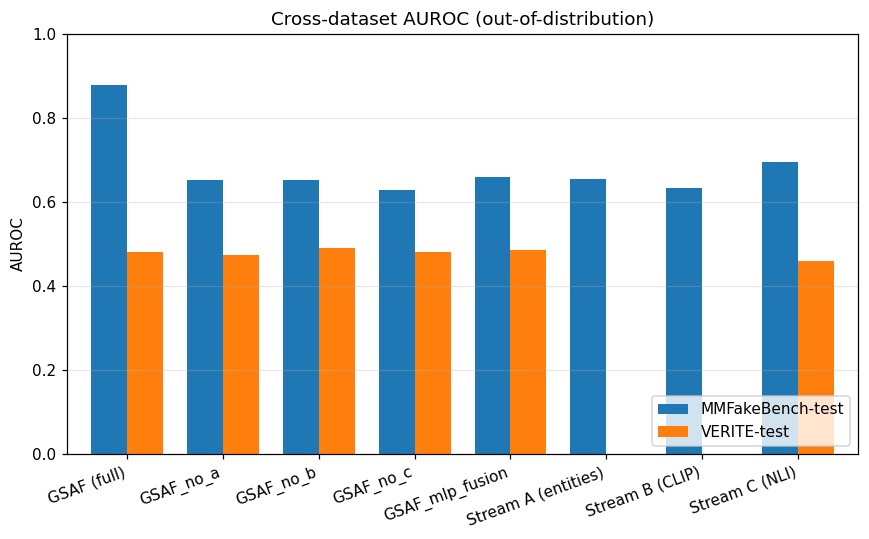

Saved: E:\eve-rag\paper\figures\cross_dataset_eval_f1_bars.png


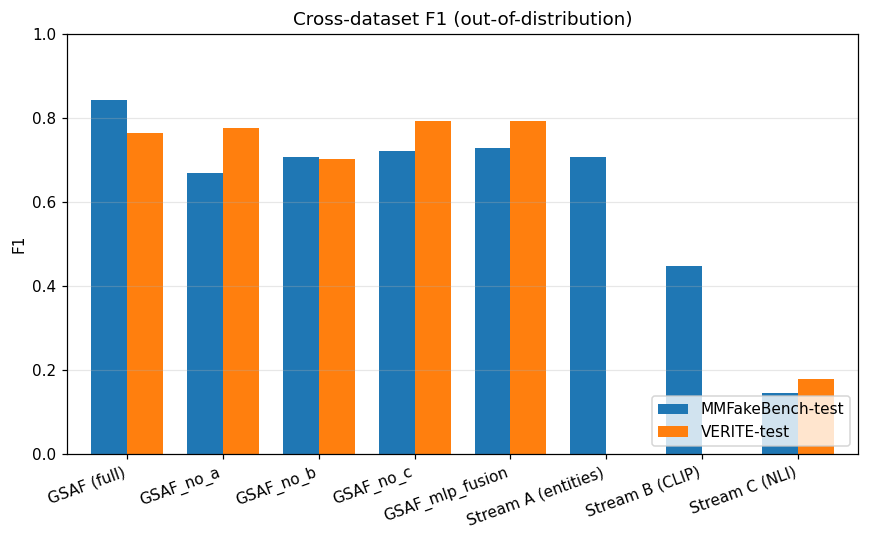

In [8]:
def plot_metric(metric, fname, ylabel):
    pivot = combined.pivot(index="model", columns="dataset", values=metric)
    pivot = pivot.reindex(combined["model"].drop_duplicates().tolist())  # preserve order
    pivot = pivot.dropna(how="all")
    fig, ax = plt.subplots(figsize=(max(8, 1.0 * len(pivot)), 5))
    pivot.plot(kind="bar", ax=ax, width=0.75)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    ax.set_title(f"Cross-dataset {ylabel} (out-of-distribution)")
    ax.set_ylim(0, 1.0)
    ax.grid(axis="y", alpha=0.3)
    ax.set_xticklabels(pivot.index, rotation=20, ha="right")
    ax.legend(title="", loc="lower right")
    plt.tight_layout()
    out = FIGURES / fname
    plt.savefig(out, bbox_inches="tight", dpi=150)
    print("Saved:", out)
    plt.show()

plot_metric("auroc", "cross_dataset_eval_auroc_bars.png", "AUROC")
plot_metric("f1",    "cross_dataset_eval_f1_bars.png",    "F1")


## 7. Headline numbers (for the paper abstract)

In [9]:
def headline(df, dataset_name):
    full = df[df["model"] == "GSAF (full)"]
    if full.empty:
        print(f"[{dataset_name}] GSAF (full) row not found.")
        return
    r = full.iloc[0]
    print(f"[{dataset_name}]  AUROC={r['auroc']:.4f} | AUPRC={r['auprc']:.4f} | F1={r['f1']:.4f} | n={int(r['n'])}")

headline(mmfb_metrics, "MMFakeBench-test")
headline(verite_metrics, "VERITE-test")


[MMFakeBench-test]  AUROC=0.8783 | AUPRC=0.9512 | F1=0.8428 | n=10000
[VERITE-test]  AUROC=0.4813 | AUPRC=0.6506 | F1=0.7633 | n=1001


---
Notes:
- All thresholds are tuned on validation, never on test.
- If a stream's prediction file does not contain rows for VERITE/MMFakeBench, that row is silently dropped.
- Compare GSAF vs the strongest individual stream and the MLP-fusion ablation to argue the gating mechanism's contribution.